In [13]:
import csv
import re

input_file = "LIG_NI_md_interactions.csv"  # your file name
residues = set()

with open(input_file, newline='') as f:
    reader = csv.DictReader(f)

    for row in reader:

        sig = row['Interaction_Signature']

        match = re.search(
            r':([A-Z0-9]{3,}\d+[A-Z])->([A-Z0-9]{3,}\d+[A-Z])',
            sig
        )

        if match:
            residues.add(match.group(1))
            residues.add(match.group(2))

# Print results
important_res = []

for res in sorted(residues):
    important_res.append(res)

print(important_res)

import pandas as pd

def checking_interactions_through_sim(input_file, output_file):

    data = pd.read_csv(input_file, header=0)

    with open(output_file, 'w') as f:
        f.write("Interaction_type,Residue_involved,Percentage\n")

    for item, item1 in zip(
            data['Interaction_Signature'],
            data['Frames_Occurred']):

        # Works for:
        # ASP134A->CU1270A
        # PHE218A->MOL7611A
        # MOL7611A->CU1270A

        parts = item.split(':')

        interaction_type = parts[0]
        resi = parts[1]

        res1, res2 = resi.split('->')

        if res1 in important_res or res2 in important_res:

            perc_val = (float(item1) * 100) / 11

            with open(output_file, 'a') as f:
                f.write(
                    f"{interaction_type},"
                    f"{res1}->{res2},"
                    f"{perc_val}\n"
                )

input_file = 'LIG_NI_md_interactions.csv'
output_file = 'interaction_check.csv'

checking_interactions_through_sim(
    input_file,
    output_file
)

['ALA170A', 'ALA366A', 'ASP363A', 'CYS322A', 'GLU223A', 'LEU319A', 'LIG800B', 'LYS169A', 'MET367A', 'NI798A', 'NI799A']


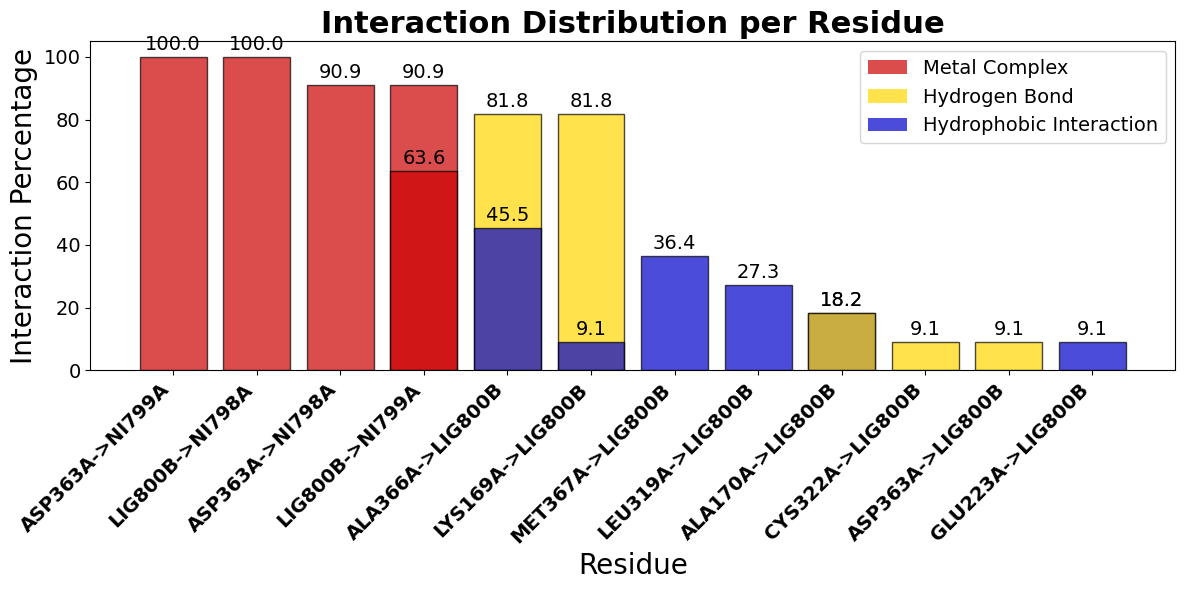

In [27]:
%matplotlib inline
from matplotlib.patches import Patch
import matplotlib.pyplot as plt
import pandas as pd

# --- 1. SAMPLE DATA PREPARATION ---
try:
    df = pd.read_csv(output_file, header=0)
    df.columns = [col.strip() for col in df.columns]
except NameError:
    print("'output_file' not found. Generating sample data to display...")
    data = {
        "Interaction_type": [
            "metal_complex",
            "metal_complex",
            "hydrogen_bond",
            "hydrophobic_interaction",
            "hydrogen_bond",
        ],
        "Residue_involved": [
            "ASP363A",
            "LIG800B",
            "ALA366A",
            "MET367A",
            "LYS169A",
        ],
        "Percentage": [75.0, 68.2, 45.0, 20.5, 15.0],
    }
    df = pd.DataFrame(data)

# Color configurations
color_map = {
    "hydrophobic_interaction": "#0000CC",   # Blue
    "hydrogen_bond": "#FFD700",             # Yellow (Gold)
    "salt_bridge": "#800080",               # Purple
    "pi_cation_interaction": "#008000",     # Green
    "pi_stack": "#FF00FF",                  # Magenta
    "metal_complex": "#CC0000",             # Red
}
colors = [color_map.get(inter, "gray") for inter in df["Interaction_type"]]


# --- 2. SINGLE GRAPH CANVAS ---
fig, ax = plt.subplots(figsize=(12, 6))

# Added alpha=0.7 for 70% transparency on the bars
bars = ax.bar(
    df["Residue_involved"],
    df["Percentage"],
    color=colors,
    edgecolor="black",
    alpha=0.7,
)

# Add value labels above bars
for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        f"{height:.1f}",
        ha="center",
        va="bottom",
        fontsize=14,
    )

ax.set_xlabel("Residue", fontsize=20)
ax.set_ylabel("Interaction Percentage", fontsize=20)
ax.set_title(
    "Interaction Distribution per Residue", fontsize=22, fontweight="bold"
)

plt.xticks(rotation=45, ha="right", fontsize=14, fontweight="bold")
plt.yticks(fontsize=14)

# --- DYNAMIC LEGEND ---
# Finds only the unique interaction types actually present in your current data
present_interactions = df["Interaction_type"].unique()

legend_elements = [
    Patch(
        facecolor=color_map.get(i, "gray"),
        label=i.replace("_", " ").title(),
        alpha=0.7,
    )
    for i in present_interactions
]
ax.legend(handles=legend_elements, fontsize=14)


# --- 3. SAVE AND DISPLAY ---
plt.tight_layout()
plt.savefig("int.png", dpi=300, bbox_inches="tight")
plt.show()